<a href="https://colab.research.google.com/github/aicoder243/lastname100-/blob/main/Mall_Customers_Clustering_Study_Guide.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mall Customer Segmentation — Beginner Study Notebook

**K-Means • Agglomerative Hierarchical Clustering • PCA**

**How to use:** Upload this notebook to [Google Colab](https://colab.research.google.com/). Download `Mall_Customers.csv` from [the Kaggle dataset](https://www.kaggle.com/datasets/simtoor/mall-customers), put it in the top level of **My Drive**, and run each code cell from top to bottom (▶ or **Shift + Enter**).

**What the symbols mean:** In a code cell, text after `#` is a *comment* for humans, not an instruction executed by Python. A variable such as `df` is a name that stores something. `df` stands for **DataFrame** (a table).

The results and plots will appear after you run the notebook in Colab. Read each explanation before moving to the next cell.

## 1. Dataset Description

**Dataset:** Mall Customer Segmentation Data  
**Source:** https://www.kaggle.com/datasets/simtoor/mall-customers  
**Original size:** 200 rows (customers) and 5 columns: `CustomerID`, `Gender`, `Age`, `Annual Income (k$)`, and `Spending Score (1-100)`.

This dataset describes customers' age, annual income, and spending scores. We can find groups of people with similar characteristics. For clustering, we use **Age, Annual Income, and Spending Score**; we leave out `CustomerID` (an arbitrary ID) and `Gender` (text, which is not directly a numeric distance). Including three features makes reducing to two PCA components meaningful.

**Your professor may ask:** Why is customer ID not useful? Because customer numbers do not measure any customer similarity.

## 2. Import Libraries

A **library** contains code written by others that we can reuse. `as pd` and `as plt` are shorter nicknames that save us typing.

In [ ]:
# pandas helps us read and work with tables.
import pandas as pd

# matplotlib helps us draw graphs.
import matplotlib.pyplot as plt

# These are machine-learning tools from scikit-learn.
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

print("Libraries loaded successfully!")

Libraries loaded successfully!


## 3. Mount Google Drive

**Mount** means connect this temporary Colab computer to the files in your Google Drive. Click ▶ next to the cell, select your Google account, and grant the requested file access if you agree.

In [ ]:
# This Google-specific library lets Colab access your Drive files.
from google.colab import drive

# Connect Drive. Your files will appear inside /content/drive/MyDrive.
drive.mount('/content/drive')

Mounted at /content/drive


## 4. Load Dataset

Place `Mall_Customers.csv` directly in **My Drive**. If you placed it inside a folder, change the path to include that folder name. `pd.read_csv()` reads a CSV file into a **DataFrame**, which we call `df`. `df.head()` displays its first five rows.

In [ ]:
# The location of your file on your Google Drive.
file_path = '/content/drive/MyDrive/DATASETS/MallCustomers.csv'

# Read the CSV file into a table called df.
df = pd.read_csv(file_path)

# Preview your data and print the table's size and column names.
print("First five customers:")
display(df.head())
print("Shape (rows, columns):", df.shape)
print("Column names:", df.columns.tolist())

First five customers:


,CustomerID,Gender,Age,Education,Marital Status,Annual Income (k$),Spending Score (1-100)
0,1,M,19,High School,Married,15,39
1,2,M,21,Graduate,Single,15,81
2,3,F,20,Graduate,Married,16,6
3,4,F,23,High School,Unknown,16,77
4,5,F,31,Uneducated,Married,17,40


Shape (rows, columns): (200, 7)
Column names: ['CustomerID', 'Gender', 'Age', 'Education ', 'Marital Status', 'Annual Income (k$)', 'Spending Score (1-100)']


**Expected size:** `(200, 5)`. If you get `FileNotFoundError`, the path or filename is not where Python expects it. Use the left sidebar **Files** (folder icon) → **drive** → **MyDrive**, find the actual file, click the three dots and select **Copy path**, then paste that into `file_path`. The filename may have spaces or slightly different spelling.

## 5. Select Numerical Features

We choose three columns because they describe the customers. We use `df[features]` to select those columns into a new table named `X`. `X.info()` shows data types and missing values. The dataset is normally complete; the check below stops with a helpful message if there are blanks.

In [ ]:
# These are the three columns that describe customer similarities.
features = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']

# Select only these columns. copy() keeps a separate table.
X = df[features].copy()

print("Selected feature information:")
X.info()
print("Missing values in each column:")
print(X.isna().sum())
display(X.head())

# Clustering needs usable numbers for every row.
if X.isna().any().any():
    raise ValueError("The selected features contain missing values. Clean them before clustering.")

Selected feature information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 3 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   Age                     200 non-null    int64
 1   Annual Income (k$)      200 non-null    int64
 2   Spending Score (1-100)  200 non-null    int64
dtypes: int64(3)
memory usage: 4.8 KB
Missing values in each column:
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


,Age,Annual Income (k$),Spending Score (1-100)
0,19,15,39
1,21,15,81
2,20,16,6
3,23,16,77
4,31,17,40


## 6. Standardize Data

Without scaling, a feature measured in larger numbers can dominate the distance calculations. `StandardScaler` converts each feature to a comparable scale (approximately zero mean and unit standard deviation). **Train the cluster models on `X_scaled`**, not on the original unscaled table.

In [ ]:
# Create the tool that puts different numerical features on the same scale.
scaler = StandardScaler()

# fit_transform learns each column's average/spread, then rescales it.
X_scaled = scaler.fit_transform(X)

# Display the first few rows of the scaled data.
scaled_table = pd.DataFrame(X_scaled, columns=features)
print("Standardized data preview:")
display(scaled_table.head())

Standardized data preview:


,Age,Annual Income (k$),Spending Score (1-100)
0,-1.424569,-1.738999,-0.434801
1,-1.281035,-1.738999,1.195704
2,-1.352802,-1.700830,-1.715913
3,-1.137502,-1.700830,1.040418
4,-0.563369,-1.662660,-0.395980


## 7. K-Means Clustering

K-Means groups customers so that similar feature values end up together. `n_clusters` is the number of groups.

**How we choose that number:** We try 2 through 8 clusters and calculate a **silhouette score** for each. A higher score indicates that, by this measure, customers are relatively close to their own group and farther from other groups. We pick the best-scoring value in this range. It is a reasonable data-based rule, **not proof of a uniquely correct number of clusters**.

`fit_predict()` does two jobs: fit the model to data, and give back a cluster label for every customer.

In [ ]:
# Compare several possible numbers of K-Means groups.
scores = {}  # This dictionary will store: number of groups -> silhouette score.

for k in range(2, 9):
    trial_model = KMeans(n_clusters=k, random_state=42, n_init=10)
    trial_labels = trial_model.fit_predict(X_scaled)
    scores[k] = silhouette_score(X_scaled, trial_labels)

# Display the score table, higher is better for this criterion.
score_table = pd.DataFrame({
    'Number of clusters': list(scores.keys()),
    'Silhouette score': list(scores.values())
})
display(score_table.round(3))

# Pick the number with the largest silhouette score.
best_k = max(scores, key=scores.get)
print("Chosen number of clusters:", best_k)

# Create and train the final K-Means model.
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
df['KMeans_Cluster'] = kmeans.fit_predict(X_scaled)

# Show the first few customers with their new group numbers.
display(df.head())
print("Customers in each K-Means cluster:")
print(df['KMeans_Cluster'].value_counts().sort_index())

,Number of clusters,Silhouette score
0,2,0.335
1,3,0.358
2,4,0.404
3,5,0.417
4,6,0.428
5,7,0.417
6,8,0.408


Chosen number of clusters: 6


,CustomerID,Gender,Age,Education,Marital Status,Annual Income (k$),Spending Score (1-100),KMeans_Cluster
0,1,M,19,High School,Married,15,39,4
1,2,M,21,Graduate,Single,15,81,4
2,3,F,20,Graduate,Married,16,6,5
3,4,F,23,High School,Unknown,16,77,4
4,5,F,31,Uneducated,Married,17,40,5


Customers in each K-Means cluster:
KMeans_Cluster
0    45
1    39
2    33
3    39
4    23
5    21
Name: count, dtype: int64


**What does a cluster label mean?** A label like `0`, `1`, or `2` is only a group identifier; the number itself does **not** mean better or worse customers.

## 8. K-Means Plot

Each dot is one customer. Its horizontal position shows annual income, vertical position shows spending score, and its color shows which K-Means cluster it belongs to. **Age was also used in the clustering**, even though this particular two-dimensional graph cannot show age.

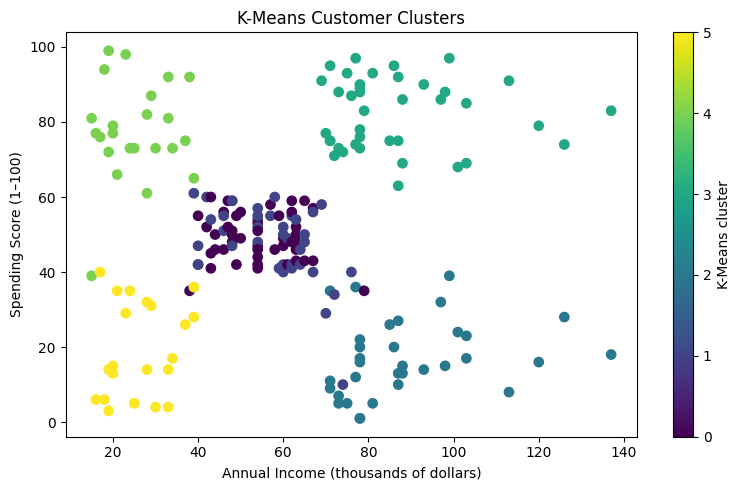

In [ ]:
# Create a blank graph.
plt.figure(figsize=(8, 5))

# Plot customer income against spending, color-coded by assigned group.
plt.scatter(
    df['Annual Income (k$)'],  # Horizontal positions
    df['Spending Score (1-100)'],  # Vertical positions
    c=df['KMeans_Cluster'],  # Dot color = cluster number
    cmap='viridis', s=45
)

plt.colorbar(label='K-Means cluster')
plt.xlabel('Annual Income (thousands of dollars)')
plt.ylabel('Spending Score (1–100)')
plt.title('K-Means Customer Clusters')
plt.tight_layout()
plt.show()

## 9. Hierarchical Clustering

**Agglomerative** means "merge upward": initially each customer is separate, and the model repeatedly merges nearby groups. We use the same `X_scaled` features and the same number of clusters as K-Means for a fair comparison.

The **Adjusted Rand Index (ARI)** compares the two ways of grouping customers. A score of **1** means identical group assignments up to renumbering; a score near **0** means little agreement beyond chance. ARI can be negative. Do not compare cluster labels like `0` vs. `0` directly because the numbering can differ.

In [ ]:
# Create a hierarchical clustering model using the same number of groups.
hierarchical = AgglomerativeClustering(n_clusters=best_k)

# Group the same standardized customers and save their labels.
df['Hierarchical_Cluster'] = hierarchical.fit_predict(X_scaled)

# Show results side by side.
display(df[['Age', 'Annual Income (k$)', 'Spending Score (1-100)',
            'KMeans_Cluster', 'Hierarchical_Cluster']].head())

# Compare the two clustering methods without being fooled by label numbers.
ari = adjusted_rand_score(df['KMeans_Cluster'], df['Hierarchical_Cluster'])
print(f'Adjusted Rand Index (ARI): {ari:.3f}')

,Age,Annual Income (k$),Spending Score (1-100),KMeans_Cluster,Hierarchical_Cluster
0,19,15,39,4,4
1,21,15,81,4,5
2,20,16,6,5,4
3,23,16,77,4,5
4,31,17,40,5,4


Adjusted Rand Index (ARI): 0.891


## 10. Hierarchical Plot

This uses the exact same x- and y-axes as the K-Means plot, so you can visually compare their groupings.

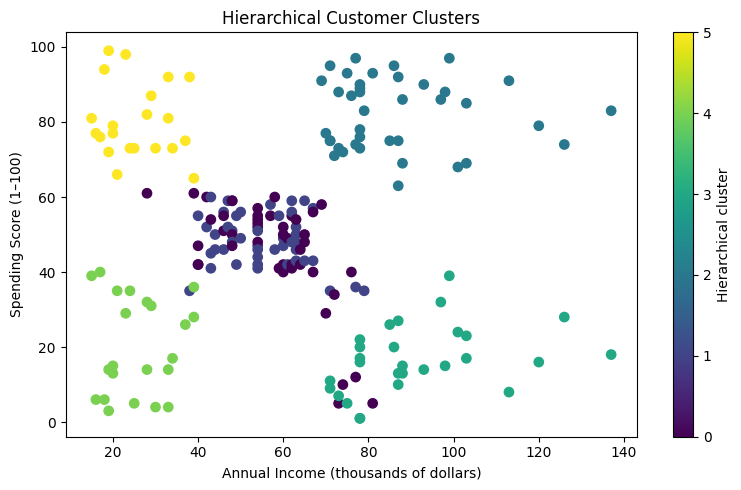

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(
    df['Annual Income (k$)'],
    df['Spending Score (1-100)'],
    c=df['Hierarchical_Cluster'],
    cmap='viridis', s=45
)
plt.colorbar(label='Hierarchical cluster')
plt.xlabel('Annual Income (thousands of dollars)')
plt.ylabel('Spending Score (1–100)')
plt.title('Hierarchical Customer Clusters')
plt.tight_layout()
plt.show()

## 11. Principal Component Analysis (PCA)

PCA changes the three standardized features into new numerical directions called **principal components**. Each component is a weighted combination of the original features. The first component captures the most variation; the second captures the most remaining variation while being independent of the first. `n_components=2` means we keep exactly two new coordinates per customer.

In [ ]:
# Ask PCA to summarize our three features in just two components.
pca = PCA(n_components=2)

# Learn the directions of variation and transform each customer's values.
X_pca = pca.fit_transform(X_scaled)

# Store those two new coordinates in our original table.
df['PC1'] = X_pca[:, 0]  # All rows, first PCA column
df['PC2'] = X_pca[:, 1]  # All rows, second PCA column

display(df[['PC1', 'PC2', 'KMeans_Cluster']].head())

,PC1,PC2,KMeans_Cluster
0,-0.615720,-1.763481,4
1,-1.665793,-1.820747,4
2,0.337862,-1.674799,5
3,-1.456573,-1.772430,4
4,-0.038465,-1.662740,5


## 12. Explained Variance

The **explained variance ratio** tells us how much of the standardized dataset's total variation a component captures. Add PC1 and PC2's ratios to see how much information these two directions preserve. The actual values appear when you run the code; **write them down for your conclusion**.

In [ ]:
# PCA calculated the fraction of total variation in each component.
variance_ratio = pca.explained_variance_ratio_

# Add both fractions together to calculate total captured variation.
total_variance = variance_ratio.sum()

print(f'PC1 explained variance: {variance_ratio[0]:.2%}')
print(f'PC2 explained variance: {variance_ratio[1]:.2%}')
print(f'Total explained variance (PC1 + PC2): {total_variance:.2%}')

PC1 explained variance: 44.27%
PC2 explained variance: 33.31%
Total explained variance (PC1 + PC2): 77.57%


## 13. PCA Plot

Each point is a customer, positioned by `PC1` and `PC2`. Colors come from the **K-Means** labels, not a new PCA clustering model. This helps us see whether the customer groups still look separated after we compress three features into two.

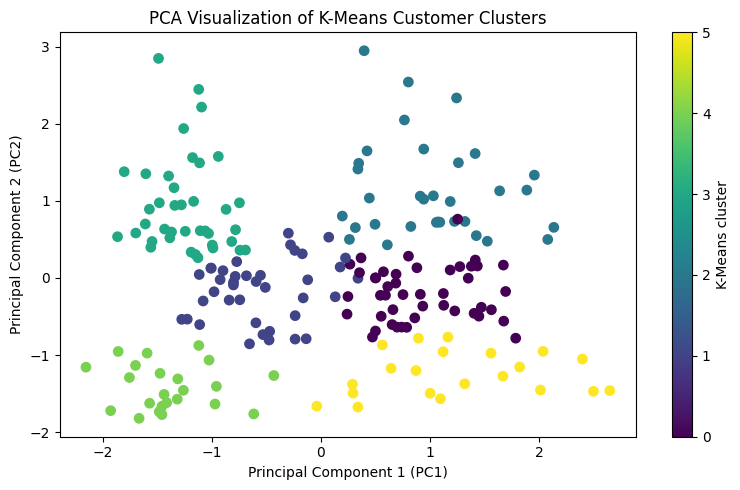

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(
    df['PC1'],  # New PCA x-coordinate
    df['PC2'],  # New PCA y-coordinate
    c=df['KMeans_Cluster'],  # Reuse K-Means groups for colors
    cmap='viridis', s=45
)
plt.colorbar(label='K-Means cluster')
plt.xlabel('Principal Component 1 (PC1)')
plt.ylabel('Principal Component 2 (PC2)')
plt.title('PCA Visualization of K-Means Customer Clusters')
plt.tight_layout()
plt.show()

## 14. Interpretation and Conclusion

**First, read your results instead of inventing findings.** We will calculate each K-Means group's average age, income, and spending. These averages help you describe what makes each group different.

In [ ]:
# Find the average customer characteristics in each K-Means group.
cluster_profile = df.groupby('KMeans_Cluster')[features].mean().round(1)
print('Average age, income, and spending score by K-Means cluster:')
display(cluster_profile)

# These values are also useful for your written comparison.
print(f'Number of groups: {best_k}')
print(f'Agreement between clustering methods (ARI): {ari:.3f}')
print(f'Total variation retained by PC1 + PC2: {total_variance:.2%}')

Average age, income, and spending score by K-Means cluster:


,Age,Annual Income (k$),Spending Score (1-100)
KMeans_Cluster,,,
0,56.3,54.3,49.1
1,26.8,57.1,48.1
2,41.9,88.9,17.0
3,32.7,86.5,82.1
4,25.0,25.3,77.6
5,45.5,26.3,19.4


Number of groups: 6
Agreement between clustering methods (ARI): 0.891
Total variation retained by PC1 + PC2: 77.57%


### Write your own conclusion after running the notebook

Replace the blanks with **your actual results**:

1. **K-Means:** "K-Means separated customers into **___** groups using age, income, and spending score. Looking at the group averages, I found that **___**."
2. **Hierarchical clustering:** "The hierarchical model also found **___** groups. The ARI between the two models was **___**, which shows **___** agreement."
3. **Explained variance:** "PC1 explained **___%** and PC2 explained **___%** of the variation. Together, they explained **___%**."
4. **Meaning of PCA:** "The PCA plot shows **___**. It helped me see **___** about the customer groups after reducing the number of features."

**Important:** Group numbers are arbitrary. Describe groups by their **characteristics**, not as "Cluster 0 is best." A two-dimensional plot can hide distinctions involving the third feature (Age).

### Submission checks

- [ ] Notebook cells run from top to bottom without errors.
- [ ] Google Drive CSV loads correctly and `df.shape` prints `(200, 5)`.
- [ ] Three plots appear, with meaningful axis labels and titles.
- [ ] Silhouette choice, ARI comparison, explained variance, and your written explanations are included.
- [ ] Colab notebook is shared with **Anyone with the link → Viewer**, if allowed by your class.
- [ ] Submit this notebook's **Colab link** and the **Kaggle dataset link**.

**Coding quiz practice:** Cover the code, then try writing the import statements, `drive.mount`, `pd.read_csv`, `df.head`, feature selection, StandardScaler, KMeans, hierarchical clustering, and PCA from memory. Explain what `fit_predict` and `fit_transform` return.